# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [4]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [6]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [7]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [8]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [9]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [10]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [11]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [12]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [21]:
# cantidad de nulos para users
print("Cantidad de valores nulos en Users")
print(users.isna().sum())
print("Proporcion de valores nulos en Users")
print(users.isna().mean())

Cantidad de valores nulos en Users
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporcion de valores nulos en Users
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [27]:
# cantidad de nulos para usage
print("Cantidad de valores nulos en Usage")
print(usage.isna().sum())
print("")
print("Proporcion de valores nulos en Usage")
print(usage.isna().mean())

Cantidad de valores nulos en Usage
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporcion de valores nulos en Usage
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

**Contamos con valores nulos en Users, en donde las columnas "city" y "churn_date" son las faltantes de datos, churn_date cuenta con 3534 celdas vacias, esto debido a que probablemente no se han dado de baja, de igual manera su porcentaje de vacios es del 88.3%, por tanto se puede ignorar, ahora, si seria importante revisar la columna de city, debido a que nefcesitaremos segmentar por ubicacion, asi que estara en revision**

**En cuando a usage, columnas "date", "duration" y "length" tienen celdas faltantes, siendo que date tiene 50, duration tiene 22076 y length cuenta con 17896 celdas con valores nulos. Es critico tener valores faltantes en duration y length porque son nuestras metricas de consumo, la cual estara en revision, y la columna city, con sus faltantes, se buscara si hay algun tipo de patron el cual sea la causa del 0.1% de los valores faltantes, o en su caso imputarlos**

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [23]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` tenemos 4000 valores indentificados, con minimos de 10,000 y maximos de 13,999, hasta aqui todo normal, con una media de 11.999.5. no contamos con valores nulos en esta columna
- La columna `age` tenemos un valor atipico en minimos de -999, distorcionando considerablemente nuestra media y desviacion estandar, ademas de que la diferencia entre media y mediana es sobresaliente, teniendo valores extremos por revisar

In [24]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`ambas tienen 40,000 registros y sus valores son normales, no contamos con valores nulos
- La columna duration tiene 17,924 registros, con una diferencia entre la media y la mediana, esto es un sesgo de valores altos, de igual manera se debe revisar los valores minimos y maximos, ya que pasamos el Q3 de 6.99 hasta el Max de 120, valor muy por arriba.
- la columna length destaca su maximo de 1490 con respecto a la mediana, estara en revision para observar si es un valor atipico o representa datos validos en los registros

In [26]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for columna in columnas_user:
    print(f"\nValores unicos de {columna}:")
    print(users[columna].unique())
    print(f"\Frecuencia de valores en {columna}:")
    print(users[columna].value_counts(dropna=False))


Valores unicos de city:
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
\Frecuencia de valores en city:
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

Valores unicos de plan:
['Basico' 'Premium']
\Frecuencia de valores en plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` presenta siete ciudades distintas, además de valores desconocidos representados mediante NaN y ?. Se identificaron 565 registros sin información válida de ciudad, por lo que será necesario investigar y tratar estos valores durante la limpieza de datos
- La columna `plan`contiene solamente dos categorias, "Basico" con un 64.9% de los usuarios y "Premium" con un 35.1%, coincidiendo con los planes disponibles en el conjunto de datos

In [30]:
# explorar columna categórica de usage
usage['type']
print("Valores unicos de type")
print(usage['type'].unique())
print("")
print("Frecuencia de valores en type")
print(usage['type'].value_counts(dropna=False))

Valores unicos de type
['call' 'text']

Frecuencia de valores en type
text    22092
call    17908
Name: type, dtype: int64


- La columna `type` contiene dos categorias, call y text, correspondiendo a mensajes de texto con 55.23% y llamadas telefonicas con 44.77%, sin valores nulos ni inconsistencias.


---
✍️ **Comentario**: como se menciono anteriormente, los valores atipicos se encuentran dentro de la columna "age" en USERS, con valores llamativos atipicos como (-999), el cual se deberia remplazar por NaN para evitar que los datos distorsionen las estadisticas y en la columna "Ciudad" con valores faltantes, en donde yo remplazaria "?" por "NaN"

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [40]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])
users['reg_date'].dtype

dtype('<M8[ns]')

In [39]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])
usage['date'].dtype

dtype('<M8[ns]')

In [47]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()


array([2022, 2026, 2023, 2024])

In [49]:
print("Cantidad de fechas nulas:")
print(users['reg_date'].isna().sum())

print("\nProporción de fechas nulas:")
print(users['reg_date'].isna().mean())

Cantidad de fechas nulas:
0

Proporción de fechas nulas:
0.0


En `reg_date`, se registran cuatro años de registro, indicando registros de clientes incorporados durante este periodo de tiempo. Se revisaran las distribuciones de registros por cada año para identificar tendencias de crecimiento y posibles inconsistencias temporales, sin valores ausentes

In [44]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

In [50]:
print("Cantidad de fechas nulas:")
print(usage['date'].isna().sum())

print("\nProporción de fechas nulas:")
print(usage['date'].isna().mean())

Cantidad de fechas nulas:
50

Proporción de fechas nulas:
0.00125


En `date`, se identifican registros correspondientes aal año 2024, pero existen de igual manera valores nulos (nan), por lo que se revisara el origen del problema antes de avanzar a la siguiente etapa de analisis
Basaremos el análisis en estas fechas.

✍️ **Comentario**: 

**Users, columna(reg_date), se encontraron registros de 2022, 2023, 2024 y 2026. Revisaria que las fechas sean correctas antes del analisis. Si encuentro años imposibles, los corregiria si puedo confirmar el dato; de lo contrario, los marcaria como NaT**

**Usage, columna(date), los registros corresponden a 2024, pero tambien hay fechas nulas, como se muetra arriba. Revisaria su cantidad y origen. Si no es posible recuperar las fechas, mantendria esos valores como NaT para evitar alterar la informacion

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [52]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [53]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [55]:
# Marcar fechas futuras como NA para reg_date
users.loc[
    (users['reg_date'].dt.year < 2022) |
    (users['reg_date'].dt.year > 2026),
    'reg_date'
] = pd.NaT

# Verificar cambios
users['reg_date'].describe()

count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [58]:
# Verificación MAR en usage (Missing At Random) para duration

print("Valores nulos en duration por tipo")
print("")
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().sum()))
print("")
print("Proporción de nulos en duration por tipo:")
print("")
print(usage.groupby('type')['duration'].apply(lambda x: x.isna().mean()))


Valores nulos en duration por tipo

type
call        0
text    22076
Name: duration, dtype: int64

Proporción de nulos en duration por tipo:

type
call    0.000000
text    0.999276
Name: duration, dtype: float64


In [59]:
# Verificación MAR en usage (Missing At Random) para length

print("Valores nulos en length por tipo")
print("")
print(usage.groupby('type')['length'].apply(lambda x: x.isna().sum()))
print("")
print("Proporción de nulos en length por tipo:")
print("")
print(usage.groupby('type')['length'].apply(lambda x: x.isna().mean()))

Valores nulos en length por tipo

type
call    17896
text        0
Name: length, dtype: int64

Proporción de nulos en length por tipo:

type
call    0.99933
text    0.00000
Name: length, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length

**Los valores nulos de duration y length dependen del tipo de registro (type). La duracion no aplica a los mensajes de texto y la longitud no aplica a las llamadas. Por lo tanto, se consideran valores ausentes estructurales y se conservaran como NaN ya que no representan errores ni informacion perdida
Se tomo esta decision debido al patron, pero tecnicamente no basta par mostrar MAR**

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [60]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [61]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [62]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [63]:
# Resumen estadístico de las columnas numéricas
columnas_numericas = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

user_profile[columnas_numericas].describe()


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,23.317054
std,17.690408,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,47.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [65]:
# Distribución porcentual del tipo de plan
print("Distribución porcentual de planes:")
print("")
print((user_profile['plan'].value_counts(normalize=True) * 100).round(2))

Distribución porcentual de planes:

Basico     64.88
Premium    35.12
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

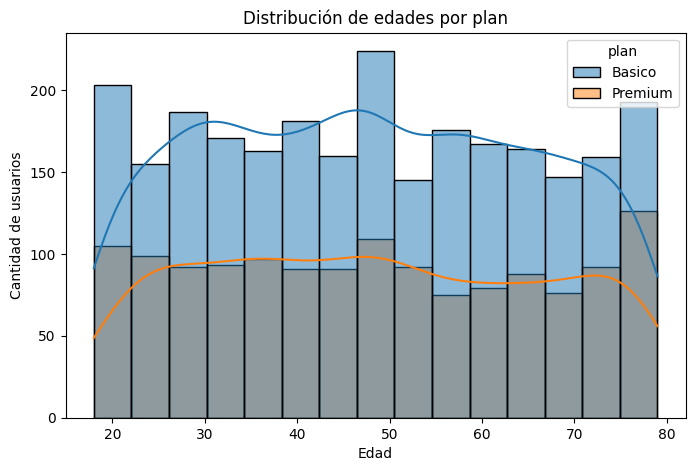

In [72]:
# Histograma para visualizar la edad (age)

plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='age', hue='plan', bins=15, kde=True)
plt.title('Distribución de edades por plan')
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: La grafica muestra como se distribuyen las edades de los usuarios y permite identificar si existe alguna diferencia entre los clientes de Basico y Premium
- Distribución simetrica

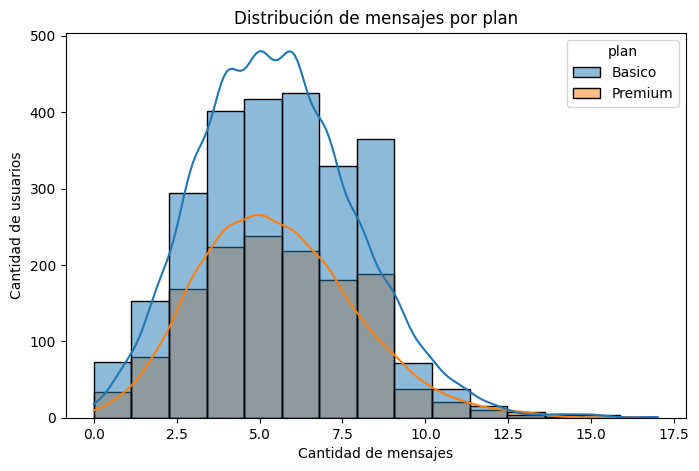

In [74]:
# Histograma para visualizar la cant_mensajes
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', bins=15, kde=True)
plt.title('Distribución de mensajes por plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: Permite observar que plan concentra a los usuarios que envian mas mensajes y si existe alguna diferencia importante entre ambos planes
- Leve sesgo hacia la derecha

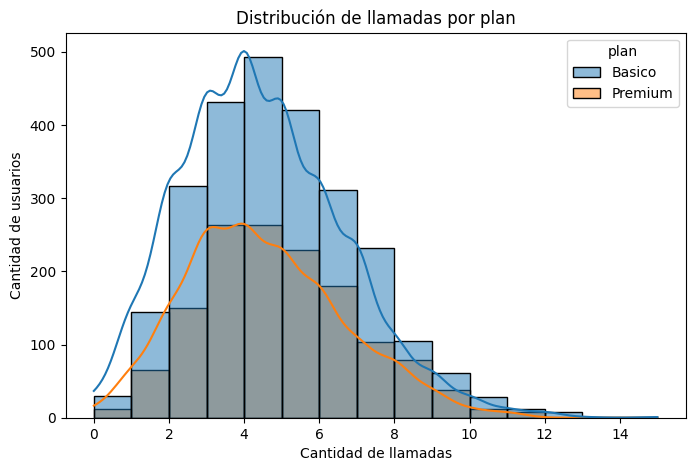

In [73]:
# Histograma para visualizar la cant_llamadas
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', bins=15, kde=True)
plt.title('Distribución de llamadas por plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: Permite comparar la cantidad de llamadas entre los dos planes e identificar cuál presenta un mayor consumo.
- Distribución sesgada a la derecha indicando menor cantidad de llamadas 

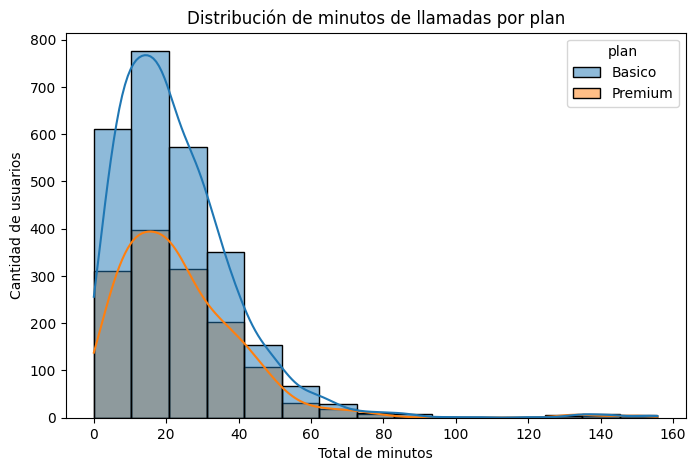

In [75]:
# Histograma para visualizar la cant_minutos_llamada
plt.figure(figsize=(8, 5))
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', bins=15, kde=True)
plt.title('Distribución de minutos de llamadas por plan')
plt.xlabel('Total de minutos')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: Permite identificar cuánto tiempo utilizan los clientes en llamadas y si existen diferencias de consumo entre Basico y Premium
- Distribucion sesgada a la derecha, indica menor duracion de llamada por cada usuario

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

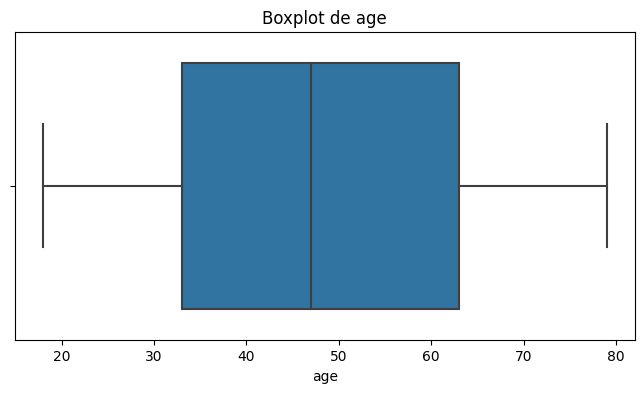

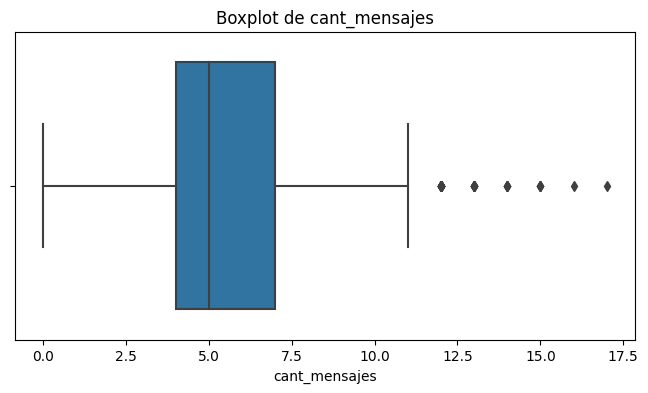

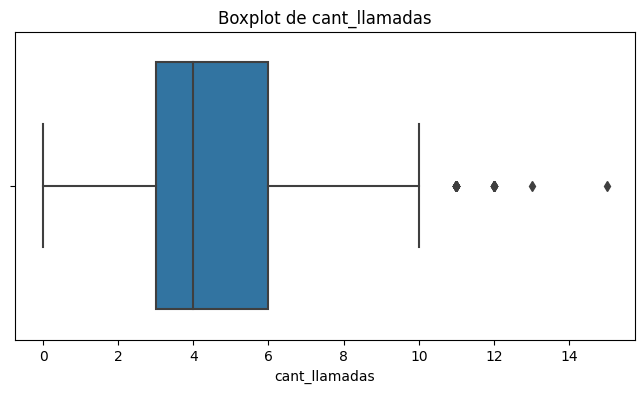

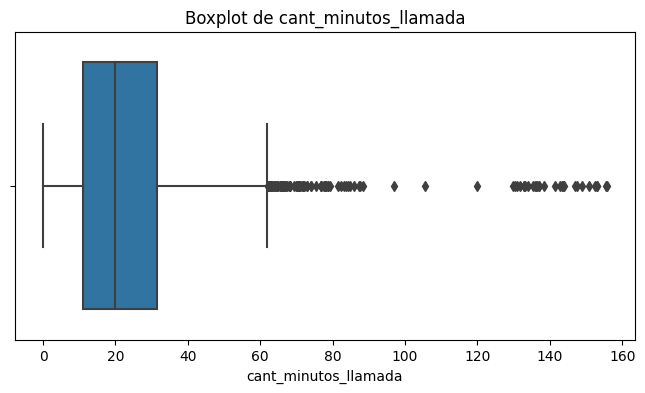

In [77]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for columna in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=columna, hue='plan')
    plt.title(f'Boxplot de {columna}')
    plt.xlabel(columna)
    plt.show()

💡Insights: Los boxplots muestran algunos valores atipicos en las variables, principalmente en el uso del servicio. Esto puede deberse a usuarios que realizan mas llamadas o envian mas mensajes que los demas. No todos estos valores son errores, por lo que considero mejor conservarlos y revisarlos antes de eliminarlos
- Age: No presenta outliers
- cant_mensajes: presenta outliers, sujeta a revision
- cant_llamadas: presenta outliers, sujeta a revision
- cant_minutos_llamada: presenta outliers, sujeta a revision

In [78]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for columna in columnas_limites:
    Q1 = user_profile[columna].quantile(0.25)
    Q3 = user_profile[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    print(f'\nVariable: {columna}')
    print(f'Límite inferior: {limite_inferior}')
    print(f'Límite superior: {limite_superior}')




Variable: cant_mensajes
Límite inferior: -0.5
Límite superior: 11.5

Variable: cant_llamadas
Límite inferior: -1.5
Límite superior: 10.5

Variable: cant_minutos_llamada
Límite inferior: -19.322500000000005
Límite superior: 61.8575


In [79]:

# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()


,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡 Insights:

- cant_mensajes: Mantener los outliers, ya que algunos usuarios pueden enviar mas mensajes que el promedio y esto representa un comportamiento normal.

- cant_llamadas: Mantener los outliers, porque algunos clientes pueden realizar mas llamadas de lo habitual sin que necesariamente sea un error.

- cant_minutos_llamada: Mantener los outliers, ya que existen usuarios que pueden acumular muchos mas minutos de llamada que otros. Aunque hay valores bastante elevados, es necesario revisarlos antes de eliminarlos.

Conclusion: Decidi conservar los outliers de las tres columnas, ya que pueden representar habitos reales de consumo de los usuarios y no necesariamente errores en los datos.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [91]:
# Crear columna grupo_uso

condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]

# Asignar grupos
grupos = ['Bajo uso', 'Uso medio']

# Crear columna grupo_uso
user_profile['grupo_uso'] = np.select(condiciones, grupos, default='Alto uso')

In [96]:
# verificar cambios
user_profile[['age', 'cant_llamadas', 'cant_mensajes', 'grupo_uso']].head()

,age,cant_llamadas,cant_mensajes,grupo_uso
0,38.0,3.0,7.0,Uso medio
1,53.0,10.0,5.0,Alto uso
2,57.0,2.0,5.0,Uso medio
3,69.0,3.0,11.0,Alto uso
4,63.0,3.0,4.0,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [93]:
# Crear columna grupo_edad

condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

grupos_edad = ['Joven', 'Adulto']

user_profile['grupo_edad'] = np.select(
    condiciones_edad,
    grupos_edad,
    default='Adulto Mayor'
)

In [95]:
# verificar cambios
user_profile[['age', 'grupo_edad', 'cant_llamadas', 'cant_mensajes', 'grupo_uso']].head(10)


,age,grupo_edad,cant_llamadas,cant_mensajes,grupo_uso
0,38.0,Adulto,3.0,7.0,Uso medio
1,53.0,Adulto,10.0,5.0,Alto uso
2,57.0,Adulto,2.0,5.0,Uso medio
3,69.0,Adulto Mayor,3.0,11.0,Alto uso
4,63.0,Adulto Mayor,3.0,4.0,Bajo uso
5,61.0,Adulto Mayor,7.0,5.0,Uso medio
6,39.0,Adulto,5.0,3.0,Uso medio
7,70.0,Adulto Mayor,5.0,3.0,Uso medio
8,76.0,Adulto Mayor,5.0,5.0,Uso medio
9,47.0,Adulto,3.0,5.0,Uso medio


In [107]:
print(user_profile[['grupo_uso', 'grupo_edad']].describe())

        grupo_uso grupo_edad
count        4000       4000
unique          3          3
top     Uso medio     Adulto
freq         2943       2018


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

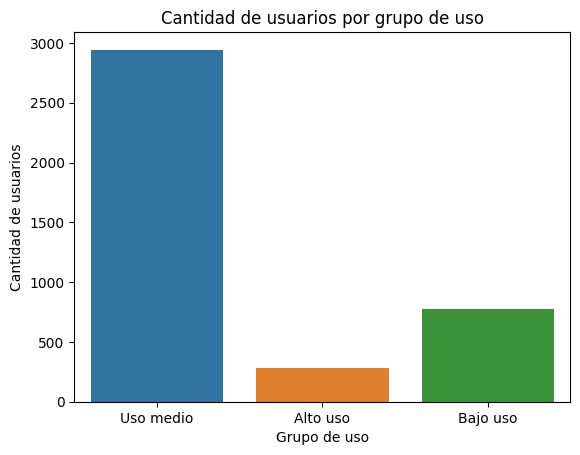

In [97]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')

plt.title('Cantidad de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()

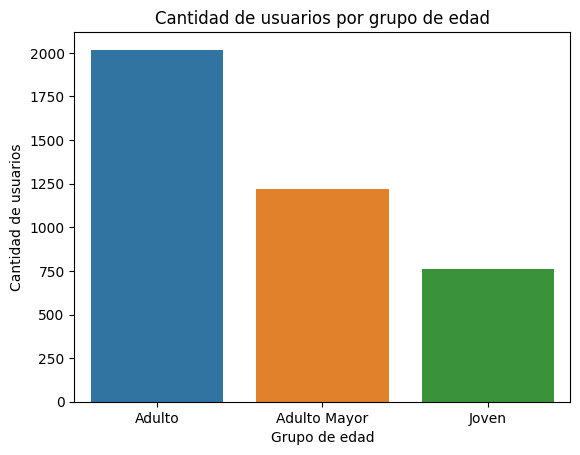

In [98]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Cantidad de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

**Durante el analisis de los datos encontre varios problemas que fue necesario corregir antes de trabajar con la informacion. Uno de ellos fueron las edades con valores incorrectos (-999), ademas de ciudades desconocidas o vacias. En la columna city encontre 565 registros sin informacion, lo que representa aproximadamente el 14.1% de los usuarios. Tambien encontre valores faltantes en las columnas de llamadas y mensajes; al revisarlos, identifique que correspondian a datos que no aplicaban a ese tipo de actividad, por lo que decidi conservarlos como valores nulos.

En cuanto a los segmentos de clientes, clasifique a los usuarios por edad y nivel de uso. El grupo mas grande por consumo fue Uso medio, con 2,943 usuarios (73.6%). Por edad, el segmento predominante fue Adulto, con 2,018 usuarios (50.45%). Esto indica que ConnectaTel tiene una base importante de clientes adultos con un consumo moderado. Sin embargo, seria necesario cruzar ambos segmentos para conocer exactamente cuantos usuarios adultos pertenecen al grupo de uso medio.

Considero que los clientes de uso medio y alto pueden representar una buena oportunidad para el negocio, ya que utilizan con mayor frecuencia los servicios de llamadas y mensajes. Por otro lado, los clientes de bajo uso tambien son importantes, porque pueden convertirse en usuarios mas activos si reciben ofertas adecuadas. Para determinar cuales son los mas rentables, seria necesario comparar sus ingresos y costos.

Durante el analisis de outliers encontre valores elevados en las variables de consumo. Los valores maximos fueron 17 mensajes, 15 llamadas y 155.69 minutos de llamada. Decidi conservar estos registros porque pueden representar habitos reales de consumo y no necesariamente errores. Para ConnectaTel, estos usuarios pueden ser una oportunidad para ofrecer paquetes con mayores beneficios o servicios adicionales.

Como recomendacion, ConnectaTel podria mantener planes de costo accesible para usuarios de bajo consumo y ofrecer paquetes con mas minutos y mensajes para quienes utilizan el servicio con mayor frecuencia. Tambien seria conveniente crear promociones dirigidas al segmento adulto, ya que representa la mayor parte de los clientes. Finalmente, recomiendo continuar analizando los habitos de consumo y la rentabilidad de cada segmento para adaptar los planes a las necesidades reales de los usuarios.

Conclusion: El analisis permitio identificar que la mayor parte de los clientes tiene un uso medio del servicio y pertenece al grupo de adultos. Esta informacion puede ayudar a ConnectaTel a mejorar sus planes, crear promociones mas especificas y aprovechar las oportunidades de crecimiento dentro de su base actual de clientes.**


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**

**Se encontraron edades incorrectas con valor -999 y ciudades desconocidas o vacias

En la columna city habia 565 registros sin informacion, aproximadamente el 14.1% del total

Tambien se encontraron valores faltantes en llamadas y mensajes que no aplicaban al tipo de actividad

La informacion de ubicacion presentaba inconsistencias, ya que algunos usuarios tenian el simbolo ? en lugar de una ciudad valida, lo que dificulta identificar correctamente su ubicacion y analizar el consumo por region**

🔍 **Segmentos por Edad**

El grupo predominante es Adulto, con 2,018 usuarios (50.45%)

Esto indica que la mayor parte de los clientes se encuentra entre los 30 y 59 años


📊 **Segmentos por Nivel de Uso**

El grupo predominante es Uso medio, con 2,943 usuarios (73.6%)

La mayoria de los clientes realiza un consumo moderado de llamadas y mensajes

➡️ Esto sugiere que ConnectaTel tiene una base de clientes principalmente adultos y con un nivel de consumo medio, por lo que podria enfocar sus estrategias en mantener a estos usuarios y conocer mejor sus necesidades


💡 **Recomendaciones**

Crear planes economicos para usuarios de bajo consumo y paquetes con mas minutos y mensajes para usuarios de alto consumo

Ofrecer promociones dirigidas al segmento adulto para mantener su preferencia

Analizar la rentabilidad de cada segmento para identificar cuales generan mayores ingresos

Revisar y corregir la informacion de ubicacion para poder realizar mejores comparaciones entre ciudades y detectar oportunidades de crecimiento por region

Revisar periodicamente los datos para evitar errores y mejorar la toma de decisiones

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`